# TP2 — Reconstrucción 3D

**Convención global:** plano ChArUco en Z=0 y +Z hacia el zapato. Los resultados PLY, las poses y la medición utilizan este mismo sistema métrico.

## 0. Imports y configuración

In [38]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import cv2
import numpy as np
import open3d as o3d
import matplotlib.pyplot as plt

from src.dataset import load_stereo_pairs, read_stereo_pair
from src.calibration import load_calibration, rectify_pair
from src.stereo import compute_disparity, reproject_to_3d
from src.pose import estimate_pose, world_from_rectified
from src.pointcloud import world_pointcloud, measure_object
from src.visualization import plot_epipolar_pair, plot_disparity, plot_pose, plot_camera_poses, camera_poses_mesh, plot_measurement

DATA_DIR = Path("i308-calib/data")
CAPTURE_DIR = DATA_DIR / "captures"
CALIBRATION_PATH = DATA_DIR / "stereo_calibration.pkl"
MAPS_PATH = DATA_DIR / "stereo_maps.pkl"
OUTPUT_DIR = Path("outputs")

EXAMPLE_INDEX = 0
N_EPIPOLAR_LINES = 8

# ChArUco, dimensiones reales en milímetros.
BOARD_GRID = (9, 13)
SQUARE_SIZE_MM = 42.0
MARKER_SIZE_MM = 31.5
ARUCO_DICTIONARY = cv2.aruco.DICT_5X5_100

# Marco global: Z positivo hacia el zapato, XY dentro de los límites del tablero.
# Rotación de 180° en X + cambio del origen a la esquina opuesta sobre Y.
BOARD_WIDTH_MM, BOARD_HEIGHT_MM = np.array(BOARD_GRID) * SQUARE_SIZE_MM
T_WORLD_BOARD = np.eye(4)
T_WORLD_BOARD[:3, :3] = np.diag([1.0, -1.0, -1.0])
T_WORLD_BOARD[1, 3] = BOARD_HEIGHT_MM

SGBM_PARAMS = {
    "min_disparity": 0,
    "num_disparities": 128,
    "block_size": 5,
    "uniqueness_ratio": 10,
}
MAX_VIEW_DEPTH_MM = 1500

# Mejor selección observada: primeras 14 capturas consecutivas.
SELECTED_VIEW_IDS = list(range(14))
VOXEL_SIZE_MM = 3.0
ROI_MARGIN_MM = SQUARE_SIZE_MM
ROI_HEIGHT_MM = 8 * SQUARE_SIZE_MM
ROI_BELOW_MM = SQUARE_SIZE_MM
OUTLIER_NEIGHBORS = 20
OUTLIER_STD_RATIO = 2.0

# ROI del objeto: límites experimentales originales de ChArUco.
# La nueva Y se obtiene al invertir su dirección y trasladar el origen.
OBJECT_X_MM = (130.0, 270.0)
OBJECT_Y_BOARD_MM = (110.0, 445.0)
OBJECT_Y_MM = (
    BOARD_HEIGHT_MM - OBJECT_Y_BOARD_MM[1],
    BOARD_HEIGHT_MM - OBJECT_Y_BOARD_MM[0],
)
PLANE_CLEARANCE_MM = 12.0

# Separación de componentes y medición.
CLUSTER_EPS_MM = 12.0
CLUSTER_MIN_POINTS = 8
MEASUREMENT_TRIM_PERCENT = 1.0  # Extremos robustos: percentiles 1 y 99.
FRUSTUM_DEPTH_MM = 40.0
CAMERA_LINE_RADIUS_MM = 1.0
CAMERA_AXIS_SIZE_MM = 2 * SQUARE_SIZE_MM


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Calibración disponible

In [39]:
calibration, stereo_maps = load_calibration(CALIBRATION_PATH, MAPS_PATH)
width, height = calibration["image_size"]
print(f"Resolución: {width} × {height} px")

Resolución: 1280 × 720 px


## 2. Capturas estéreo

In [40]:
stereo_pairs = load_stereo_pairs(CAPTURE_DIR)

## 3. Rectificación

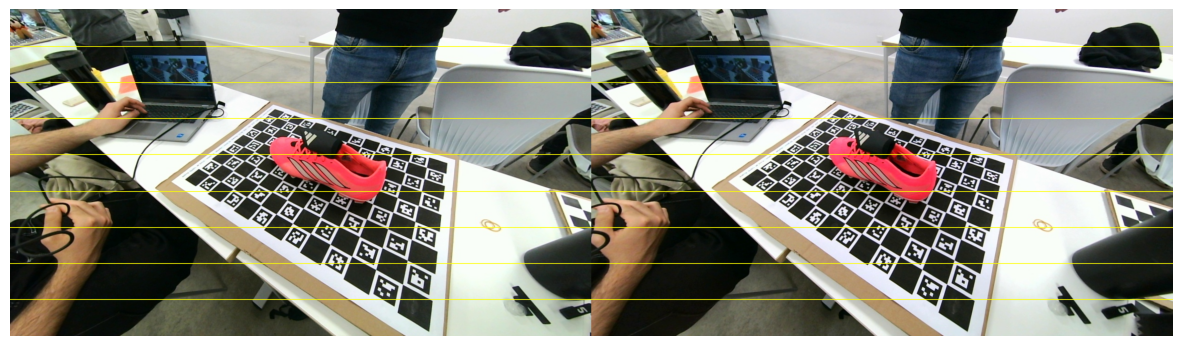

In [41]:
capture_id = list(stereo_pairs)[EXAMPLE_INDEX]
left, right = read_stereo_pair(stereo_pairs[capture_id])
left_rect, right_rect = rectify_pair(left, right, stereo_maps)
plot_epipolar_pair(left_rect, right_rect, n_lines=N_EPIPOLAR_LINES)

## 4. Disparidad y nube local

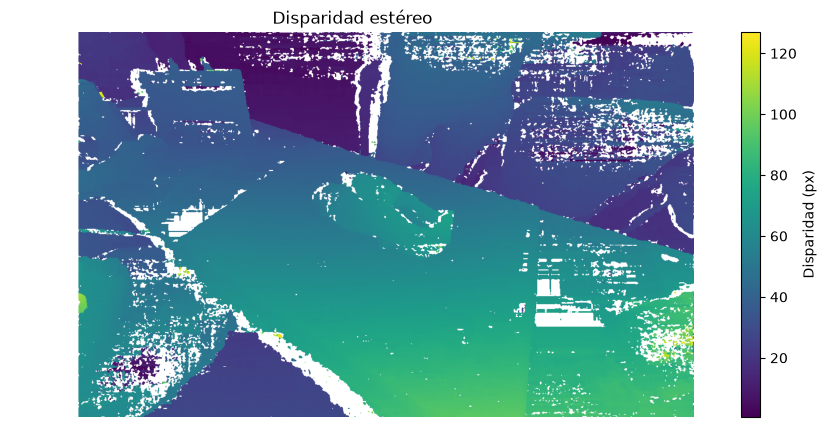

In [42]:
disparity = compute_disparity(left_rect, right_rect, **SGBM_PARAMS)
plot_disparity(disparity, SGBM_PARAMS["min_disparity"])

## 5. Pose del tablero

In [43]:
board = cv2.aruco.CharucoBoard(
    BOARD_GRID,
    SQUARE_SIZE_MM,
    MARKER_SIZE_MM,
    cv2.aruco.getPredefinedDictionary(ARUCO_DICTIONARY),
)
charuco_params = cv2.aruco.CharucoParameters()
charuco_params.cameraMatrix = calibration["left_K"]
charuco_params.distCoeffs = calibration["left_dist"]
detector = cv2.aruco.CharucoDetector(board, charuco_params)

poses = {}
for image_id, paths in stereo_pairs.items():
    image_left, _ = read_stereo_pair(paths)
    pose = estimate_pose(
        image_left, detector, calibration["left_K"], calibration["left_dist"]
    )
    if pose is not None:
        poses[image_id] = pose

print(f"Poses recuperadas: {len(poses)}/{len(stereo_pairs)}")
if not poses:
    raise ValueError("No se pudieron detectar suficientes esquinas ChArUco.")

Poses recuperadas: 27/28


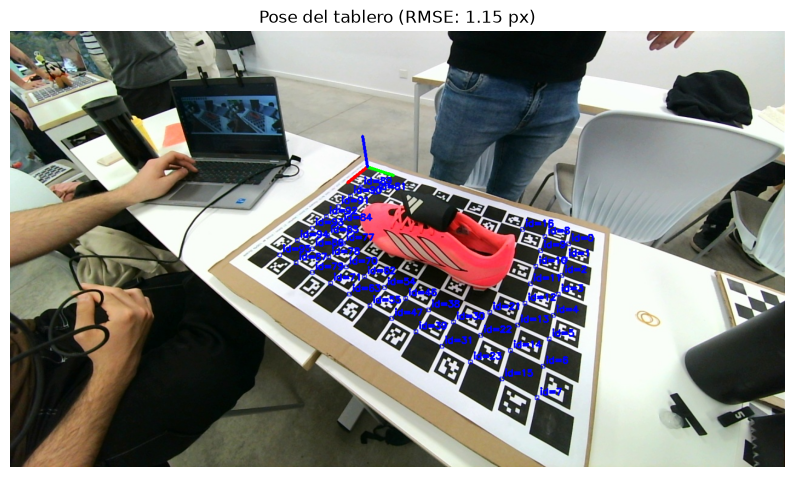

In [44]:
pose_id = next(iter(poses))
pose_left, _ = read_stereo_pair(stereo_pairs[pose_id])
plot_pose(
    pose_left, poses[pose_id], calibration["left_K"],
    calibration["left_dist"], 2 * SQUARE_SIZE_MM, T_WORLD_BOARD,
)

## 6. Fusión, recorte y vóxeles — `preview_roi.ply`

La nube global se obtiene con la calibración estéreo y la pose PnP de cada captura. La transformación incluye **un cambio rígido de marco**: el tablero permanece en Z=0 y el zapato queda hacia +Z; su escala y geometría no cambian. Utilizamos **las 14 primeras vistas consecutivas** (`SELECTED_VIEW_IDS`), que fueron las que produjeron el mejor resultado visual. La selección aumenta la limpieza a costa de cobertura angular: no garantiza observar toda la superficie.

- **SGBM:** `min_disparity=0`, `num_disparities=128`, `block_size=5`, `uniqueness_ratio=10`. La búsqueda de 128 disparidades cubre las vistas seleccionadas; el bloque de 5 píxeles y la verificación de unicidad equilibran detalle y correspondencias falsas.
- **Profundidad:** `MAX_VIEW_DEPTH_MM=1500` descarta puntos lejanos en cada cámara rectificada antes del cambio de coordenadas.
- **ROI global:** caja alineada con ChArUco, con un margen lateral de **42 mm**, **336 mm** sobre el plano (Z positivo) y **42 mm** por debajo. Conserva objeto y tablero, y descarta buena parte del fondo.
- **Vóxeles:** `VOXEL_SIZE_MM=3` reduce la redundancia por vista y tras la fusión. Es una resolución espacial, no un método para rellenar huecos.

Todos los valores pueden ajustarse en la celda de configuración.

In [45]:
# Todo el procesamiento posterior usa el marco global: tablero en Z=0, zapato en Z>0.
roi = o3d.geometry.AxisAlignedBoundingBox(
    np.array([-ROI_MARGIN_MM, -ROI_MARGIN_MM, -ROI_BELOW_MM]),
    np.array([
        BOARD_WIDTH_MM + ROI_MARGIN_MM,
        BOARD_HEIGHT_MM + ROI_MARGIN_MM,
        ROI_HEIGHT_MM,
    ]),
)

In [46]:
fused = o3d.geometry.PointCloud()

for image_id in SELECTED_VIEW_IDS:
    left_i, right_i = read_stereo_pair(stereo_pairs[image_id])
    left_i, right_i = rectify_pair(left_i, right_i, stereo_maps)
    disparity_i = compute_disparity(left_i, right_i, **SGBM_PARAMS)
    points_i, colors_i = reproject_to_3d(
        disparity_i, left_i, stereo_maps["Q"], SGBM_PARAMS["min_disparity"]
    )
    valid = (points_i[:, 2] > 0) & (points_i[:, 2] <= MAX_VIEW_DEPTH_MM)

    T_world_rect = world_from_rectified(poses[image_id], stereo_maps["R1"], T_WORLD_BOARD)
    cloud_i = world_pointcloud(points_i[valid], colors_i[valid], T_world_rect, roi)
    fused += cloud_i.voxel_down_sample(VOXEL_SIZE_MM)

fused = fused.voxel_down_sample(VOXEL_SIZE_MM)
OUTPUT_DIR.mkdir(exist_ok=True)
o3d.io.write_point_cloud(str(OUTPUT_DIR / "preview_roi.ply"), fused, write_ascii=False)
print(f"ROI: {len(fused.points):,} puntos")

ROI: 211,351 puntos


## 7. Filtrado estadístico — `preview_clean.ply`

`remove_statistical_outlier` calcula la distancia media de cada punto a sus **20 vecinos** (`OUTLIER_NEIGHBORS`) y descarta los que exceden la media global en **2 desviaciones estándar** (`OUTLIER_STD_RATIO`). Elimina ruido aislado; no sustituye al recorte espacial. Se conserva `preview_roi.ply` para comparar ambas etapas.

In [47]:
cleaned, _ = fused.remove_statistical_outlier(
    nb_neighbors=OUTLIER_NEIGHBORS,
    std_ratio=OUTLIER_STD_RATIO,
)

o3d.io.write_point_cloud(str(OUTPUT_DIR / "preview_clean.ply"), cleaned, write_ascii=False)
print(f"Clean: {len(cleaned.points):,} puntos ({len(fused.points) - len(cleaned.points):,} eliminados)")

Clean: 207,417 puntos (3,934 eliminados)


## 8. Segmentación del zapato — `preview_object.ply`

La caja se define en el marco global (tablero en **Z=0**, zapato en **+Z**). Las coordenadas X=130–270 mm provienen del recorte experimental previo. Los límites de Y se convierten automáticamente desde el marco original del ChArUco mediante `BOARD_HEIGHT_MM - Y`, para conservar **exactamente la misma región física**.

`PLANE_CLEARANCE_MM=12` separa el tablero, pero puede eliminar puntos próximos a la suela; conservamos `preview_clean.ply` para comparar.

In [48]:
object_roi = o3d.geometry.AxisAlignedBoundingBox(
    np.array([OBJECT_X_MM[0], OBJECT_Y_MM[0], PLANE_CLEARANCE_MM]),
    np.array([OBJECT_X_MM[1], OBJECT_Y_MM[1], ROI_HEIGHT_MM]),
)
object_cloud = cleaned.crop(object_roi)
o3d.io.write_point_cloud(
    str(OUTPUT_DIR / "preview_object.ply"), object_cloud, write_ascii=False
)
print(f"Objeto: {len(object_cloud.points):,} puntos")

Objeto: 29,149 puntos


## 9. Componentes conectadas — `preview_clustered.ply`

Separamos grupos de puntos por proximidad con DBSCAN, usando `eps=12 mm` (cuatro vóxeles de 3 mm) y `min_points=8`. Conservamos el grupo con más puntos como candidato al zapato. Es un filtro **exploratorio**: si una zona real queda desconectada por falta de textura, también puede desaparecer.

In [ ]:
labels = np.asarray(object_cloud.cluster_dbscan(
    eps=CLUSTER_EPS_MM, min_points=CLUSTER_MIN_POINTS
))
cluster_ids = labels[labels >= 0]
main_cluster = np.bincount(cluster_ids).argmax()
clustered = object_cloud.select_by_index(np.flatnonzero(labels == main_cluster))

o3d.io.write_point_cloud(
    str(OUTPUT_DIR / "preview_clustered.ply"), clustered, write_ascii=False
)
print(f"Cluster {len(clustered.points):,}")

ROI 211,351 → Clean 207,417 → Objeto 29,149 → Cluster 28,978


## 10. Validación geométrica — poses en el marco global (Z hacia arriba)

La figura representa el tablero, la nube segmentada, los centros de las **27 poses recuperadas** (gris) y los **14 frustums seleccionados** (naranja). Usamos la transformación cámara rectificada → mundo, incluyendo `R1` y `T_WORLD_BOARD`, para que las orientaciones coincidan con las nubes generadas a partir de `Q`.

Se utiliza Matplotlib para evitar el fallo del visualizador nativo de Open3D observado en Jupyter; las operaciones de la nube siguen realizándose con Open3D. `FRUSTUM_DEPTH_MM=40` define solamente el tamaño de los símbolos de cámara en la figura, no una profundidad reconstruida.

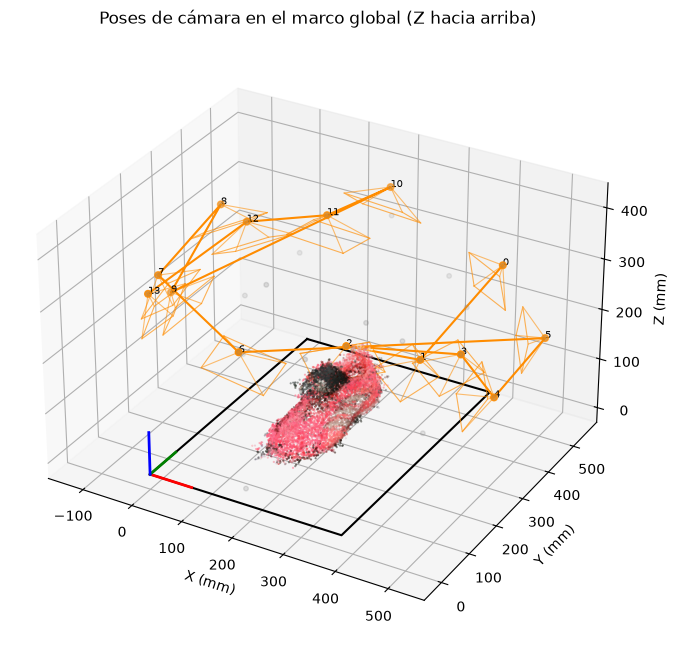

In [50]:
fig = plot_camera_poses(
    poses, SELECTED_VIEW_IDS, stereo_maps["R1"], T_WORLD_BOARD,
    stereo_maps["P1"][:3, :3], calibration["image_size"],
    board_size_mm=np.array(BOARD_GRID) * SQUARE_SIZE_MM,
    cloud=clustered, frustum_depth_mm=FRUSTUM_DEPTH_MM,
)
fig.savefig(OUTPUT_DIR / "camera_poses.png", dpi=170, bbox_inches="tight")
plt.show()

### Visualización interactiva en MeshLab

Exportamos un **PLY adicional con las 14 cámaras seleccionadas** como pirámides 3D (naranja), el borde del ChArUco (gris) y los ejes globales (RGB). Todas las geometrías utilizan el mismo marco métrico que `shoe_final.ply`. Las pirámides son símbolos para visualizar poses: `FRUSTUM_DEPTH_MM` controla su tamaño y `CAMERA_LINE_RADIUS_MM` su grosor, sin intervenir en la reconstrucción.

En MeshLab, importar `camera_poses.ply` y `shoe_final.ply` como **dos capas**, para mostrar u ocultar las cámaras sin alterar la nube del objeto.

In [51]:
camera_mesh = camera_poses_mesh(
    poses, SELECTED_VIEW_IDS, stereo_maps["R1"], T_WORLD_BOARD,
    stereo_maps["P1"][:3, :3], calibration["image_size"],
    (BOARD_WIDTH_MM, BOARD_HEIGHT_MM),
    FRUSTUM_DEPTH_MM, CAMERA_LINE_RADIUS_MM, CAMERA_AXIS_SIZE_MM,
)
o3d.io.write_triangle_mesh(
    str(OUTPUT_DIR / "camera_poses.ply"), camera_mesh, write_ascii=False
)

True

## 11. Medición métrica

La longitud principal se estima por **PCA en el plano XY del tablero**; la dirección perpendicular da el ancho. La altura se mide **respecto del plano ChArUco Z = 0**, suponiendo que el zapato está apoyado en él. Esta restricción impide que una OBB 3D libre incline el eje vertical por la cobertura parcial.

Usamos percentiles **1–99** (`MEASUREMENT_TRIM_PERCENT=1`) sobre las proyecciones para reducir la influencia de puntos periféricos; esto puede subestimar los extremos reales. La altura corresponde al percentil superior de la distancia al plano del tablero, no al rango Z de la nube (que perdió puntos de la suela al segmentar). Por ello las medidas son **estimaciones condicionadas a la cobertura** de las 14 vistas.

Largo: 288.5 mm · Ancho: 98.4 mm · Alto: 114.3 mm


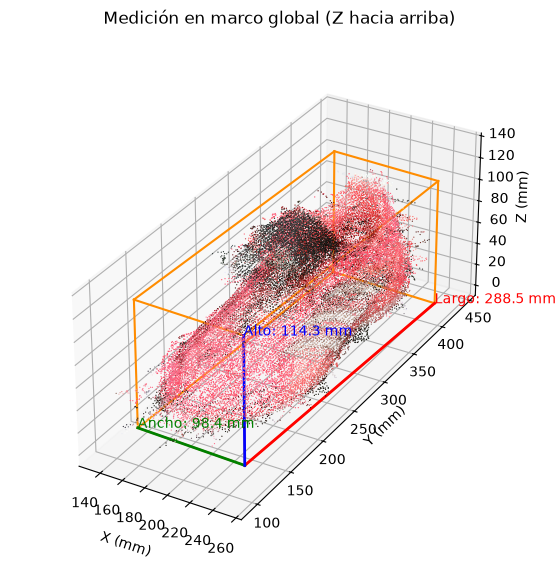

In [52]:
dimensions, measurement_box = measure_object(
    clustered, trim_percent=MEASUREMENT_TRIM_PERCENT
)
print(
    f"Largo: {dimensions['length_mm']:.1f} mm · "
    f"Ancho: {dimensions['width_mm']:.1f} mm · "
    f"Alto: {dimensions['height_mm']:.1f} mm"
)

fig = plot_measurement(clustered, measurement_box)
fig.savefig(OUTPUT_DIR / "measurement.png", dpi=170, bbox_inches="tight")
plt.show()

## 12. Exportación final

El `.ply` binario conserva la nube segmentada y el color RGB. No se exportan las nubes densas intermedias; se conservan los PLY de **ROI**, **clean**, **object** y **clustered** para mostrar el efecto de cada operación. La caja de medición es una construcción geométrica auxiliar y no altera el PLY final. `camera_poses.ply` contiene solamente la geometría de las cámaras y el tablero para inspección en MeshLab.

In [53]:
FINAL_PATH = OUTPUT_DIR / "shoe_final.ply"
o3d.io.write_point_cloud(str(FINAL_PATH), clustered, write_ascii=False)
print(f"Nube final: {len(clustered.points):,} puntos · {FINAL_PATH}")

Nube final: 28,978 puntos · outputs/shoe_final.ply
